# NYC Yellow Taxi 2017: Fare Prediction with Linear Regression

Pipeline: load data, clean, detect/impute outliers, engineer features, model, evaluate.

In [3]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm
from statsmodels.formula.api import ols
import missingno as msno
import os
from pathlib import Path


In [4]:
file_path = "C:/Users/bhanu/Documents/AI_Engineering/Python/Projects/Linear_Regression_Using_Scikit_Learn/src/data/2017_Yellow_Taxi_Trip_Data.csv"
df0 = pd.read_csv(file_path)
df = df0.copy()
print(f"The shape of dataset: {df.shape}")
print()
df.info()


The shape of dataset: (22699, 18)

<class 'pandas.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             22699 non-null  int64  
 1   VendorID               22699 non-null  int64  
 2   tpep_pickup_datetime   22699 non-null  str    
 3   tpep_dropoff_datetime  22699 non-null  str    
 4   passenger_count        22699 non-null  int64  
 5   trip_distance          22699 non-null  float64
 6   RatecodeID             22699 non-null  int64  
 7   store_and_fwd_flag     22699 non-null  str    
 8   PULocationID           22699 non-null  int64  
 9   DOLocationID           22699 non-null  int64  
 10  payment_type           22699 non-null  int64  
 11  fare_amount            22699 non-null  float64
 12  extra                  22699 non-null  float64
 13  mta_tax                22699 non-null  float64
 14  tip_amount             22699 n

## Data Cleaning

In [5]:
df.isna()
print(df.drop_duplicates().shape)
print(df.isna().sum())
print(df.head(5))


(22699, 18)
Unnamed: 0               0
VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
store_and_fwd_flag       0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
dtype: int64
   Unnamed: 0  VendorID    tpep_pickup_datetime   tpep_dropoff_datetime  \
0    24870114         2   03/25/2017 8:55:43 AM   03/25/2017 9:09:47 AM   
1    35634249         1   04/11/2017 2:53:28 PM   04/11/2017 3:19:58 PM   
2   106203690         1   12/15/2017 7:26:56 AM   12/15/2017 7:34:08 AM   
3    38942136         2   05/07/2017 1:17:59 PM   05/07/2017 1:48:14 PM   
4    30841670         2  04/15/2017 11:32:20 PM  04/15/2017 11:49:03 PM   

   passenger_count  trip_distance  Rat

## Descriptive analysis

In [8]:
print(df.describe())


         Unnamed: 0      VendorID  passenger_count  trip_distance  \
count  2.269900e+04  22699.000000     22699.000000   22699.000000   
mean   5.675849e+07      1.556236         1.642319       2.913313   
std    3.274493e+07      0.496838         1.285231       3.653171   
min    1.212700e+04      1.000000         0.000000       0.000000   
25%    2.852056e+07      1.000000         1.000000       0.990000   
50%    5.673150e+07      2.000000         1.000000       1.610000   
75%    8.537452e+07      2.000000         2.000000       3.060000   
max    1.134863e+08      2.000000         6.000000      33.960000   

         RatecodeID  PULocationID  DOLocationID  payment_type   fare_amount  \
count  22699.000000  22699.000000  22699.000000  22699.000000  22699.000000   
mean       1.043394    162.412353    161.527997      1.336887     13.026629   
std        0.708391     66.633373     70.139691      0.496211     13.243791   
min        1.000000      1.000000      1.000000      1.000000 

## Convert pickup & dropoff columns to datetime

First check the format of the data.

In [9]:
print(df["tpep_pickup_datetime"][0])


03/25/2017 8:55:43 AM


In [10]:
df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"])
df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"])
print("Data type of pickup column: ", df["tpep_pickup_datetime"].dtype)
print("Data type of dropoff column: ", df["tpep_dropoff_datetime"].dtype)
print(df[["tpep_pickup_datetime", "tpep_dropoff_datetime"]].head())


Data type of pickup column:  datetime64[us]
Data type of dropoff column:  datetime64[us]
  tpep_pickup_datetime tpep_dropoff_datetime
0  2017-03-25 08:55:43   2017-03-25 09:09:47
1  2017-04-11 14:53:28   2017-04-11 15:19:58
2  2017-12-15 07:26:56   2017-12-15 07:34:08
3  2017-05-07 13:17:59   2017-05-07 13:48:14
4  2017-04-15 23:32:20   2017-04-15 23:49:03


## Create duration column

A new column called `duration` that represents the total number of minutes each taxi ride took.

In [11]:
df["duration"] = (
    (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"])
    .dt.total_seconds()
    .div(60)
    .round()
    .astype(int)
)
print(df["duration"])


0        14
1        26
2         7
3        30
4        17
         ..
22694     3
22695    41
22696     4
22697    12
22698    13
Name: duration, Length: 22699, dtype: int64


## Outliers

In [12]:
print(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Unnamed: 0             22699 non-null  int64         
 1   VendorID               22699 non-null  int64         
 2   tpep_pickup_datetime   22699 non-null  datetime64[us]
 3   tpep_dropoff_datetime  22699 non-null  datetime64[us]
 4   passenger_count        22699 non-null  int64         
 5   trip_distance          22699 non-null  float64       
 6   RatecodeID             22699 non-null  int64         
 7   store_and_fwd_flag     22699 non-null  str           
 8   PULocationID           22699 non-null  int64         
 9   DOLocationID           22699 non-null  int64         
 10  payment_type           22699 non-null  int64         
 11  fare_amount            22699 non-null  float64       
 12  extra                  22699 non-null  float64       
 13  mta_tax     

Keeping in mind that many of the features will not be used to fit the model, the most important columns to check for outliers are likely to be:

- `trip_distance`
- `fare_amount`
- `duration`

Plot a box plot for each of these features.

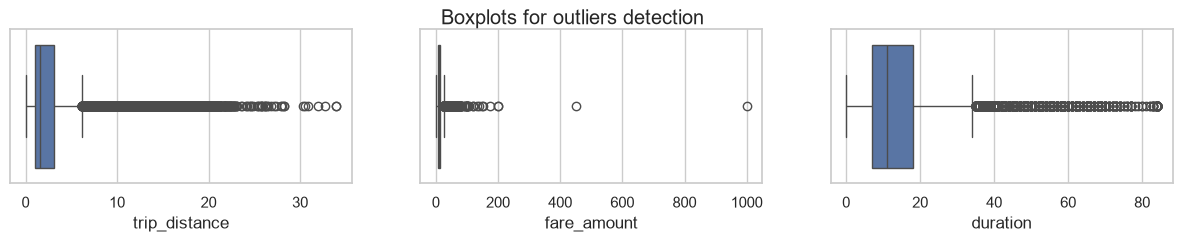

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15, 2))
fig.suptitle("Boxplots for outliers detection")
sns.boxplot(ax=axes[0], x=df["trip_distance"])
sns.boxplot(ax=axes[1], x=df["fare_amount"])
sns.boxplot(ax=axes[2], x=df["duration"])
plt.show()


All 3 variables contain outliers. The `trip_distance` variable has the highest number of extreme values; points outside the whiskers are visible, located primarily on the right side, with very few on the left. For `trip_distance`, typical values fall within the 0 to 5-mile range, but there are outliers that exceed this range, extending up to 35 miles. A 35-mile trip in New York is plausible, but there are instances with values of 0 (or close to 0) for fares or trip durations that do not add up and require investigation. There are instances of 0 distance and 0 duration, where the only logical conclusion is that the trip was either cancelled before it began or that a system error occurred.

In the chart for `fare_amount`, negative values can be seen (below zero). This is impossible, as no passenger could have paid a negative amount; it is often the result of refunds, adjusted charges, or data entry errors that must be filtered out or cleaned up before training any model.

## Imputations

### `trip_distance` outliers

In [13]:
print(sorted(set(df["trip_distance"]))[:10])


[0.0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09]


The fact that the values range from 0.0 to 0.01 and so on indicates that the system records the distance traveled with high precision. Therefore, many of these zeros or infinitesimal distances do, in fact, correspond to actual, extremely short trips, rather than necessarily being "bad data", though a few extreme cases may still require a review of their fares.

In [14]:
print(sum(df["trip_distance"] == 0))


148


148 out of ~23,000 rides is relatively insignificant. You could impute it with a value of 0.01, but it's unlikely to have much of an effect on the model. Therefore, the `trip_distance` column will remain untouched with regard to outliers.

### `fare_amount` outliers

In [15]:
print(df["fare_amount"].describe())


count    22699.000000
mean        13.026629
std         13.243791
min       -120.000000
25%          6.500000
50%          9.500000
75%         14.500000
max        999.990000
Name: fare_amount, dtype: float64


The range of values in the `fare_amount` column is large and the extremes don't make much sense.

**Low values:** Negative values are problematic. Values of zero could be legitimate if the taxi logged a trip that was immediately canceled.

**High values:** The maximum fare amount in this dataset is nearly $1,000, which seems very unlikely. High values for this feature can be capped based on intuition and statistics. The interquartile range (IQR) is $8. The standard formula of Q3 + (1.5 * IQR) yields $26.50, which doesn't seem appropriate for the maximum fare cap. In this case, we'll use a factor of 6, which results in a cap of $62.50.

In [16]:
df.loc[df["fare_amount"] < 0, "fare_amount"] = 0
print(df["fare_amount"].describe())


count    22699.000000
mean        13.033832
std         13.212462
min          0.000000
25%          6.500000
50%          9.500000
75%         14.500000
max        999.990000
Name: fare_amount, dtype: float64


Now impute the maximum value as Q3 + (6 * IQR).

In [ ]:
def outlier_imputer(column_list, iqr_factor):
    for col in column_list:
        minimum = df.loc[df[col] < 0, col] = 0
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        upper_limit = q3 + (iqr_factor * iqr)
        print(col)
        print("minimum:", minimum)
        print("q3:", q3)
        print("q1:", q1)
        print("upper_limit:", upper_limit)
        print()
        df.loc[df[col] > upper_limit, col] = upper_limit
        print(df[col].describe())
        print()


### `duration` outliers

In [18]:
print(df["duration"].describe())
print(outlier_imputer(["duration"], 6))


count    22699.000000
mean        17.012952
std         61.998403
min        -17.000000
25%          7.000000
50%         11.000000
75%         18.000000
max       1440.000000
Name: duration, dtype: float64
duration
minimum: 0
q3: 18.0
q1: 7.0
upper_limit: 84.0

count    22699.000000
mean        14.443368
std         11.854509
min          0.000000
25%          7.000000
50%         11.000000
75%         18.000000
max         84.000000
Name: duration, dtype: float64

None


## Feature engineering

### `mean_distance` column

In [19]:
df["pickup_dropoff"] = (
    df["PULocationID"].astype(str) + " " + df["DOLocationID"].astype(str)
)
print(df["pickup_dropoff"].head(2))

grouped = df.groupby("pickup_dropoff").mean(numeric_only=True)[["trip_distance"]]
print(grouped[:5])
grouped_dict = grouped.to_dict()
grouped_dict = grouped_dict["trip_distance"]
df["mean_distance"] = df["pickup_dropoff"].copy()
df["mean_distance"] = df["mean_distance"].map(grouped_dict)
print(df[(df["PULocationID"] == 100) & (df["DOLocationID"] == 231)][["mean_distance"]])


0    100 231
1     186 43
Name: pickup_dropoff, dtype: str
                trip_distance
pickup_dropoff               
1 1                  2.433333
10 148              15.700000
100 1               16.890000
100 100              0.253333
100 107              1.180000
       mean_distance
0           3.521667
4909        3.521667
16636       3.521667
18134       3.521667
19761       3.521667
20581       3.521667


### `mean_duration` column

In [20]:
df["pickup_dropoff"] = (
    df["PULocationID"].astype(str) + " " + df["DOLocationID"].astype(str)
)
group = df.groupby("pickup_dropoff").mean(numeric_only=True)[["duration"]]
grouped_dicted = group.to_dict()
grouped_dicted = grouped_dicted["duration"]
df["mean_duration"] = df["pickup_dropoff"].copy()
df["mean_duration"] = df["mean_duration"].map(grouped_dicted)
print(df[(df["PULocationID"] == 100) & (df["DOLocationID"] == 231)][["mean_duration"]])


       mean_duration
0               23.0
4909            23.0
16636           23.0
18134           23.0
19761           23.0
20581           23.0


### `day` and `month` columns

In [21]:
df["day"] = df["tpep_pickup_datetime"].dt.day_name().str.lower()
df["month"] = df["tpep_pickup_datetime"].dt.strftime("%b").str.lower()


### `rush_hour` column

A ride is flagged as rush hour if it is on a weekday (not Saturday or Sunday) **and** either from 06:00-10:00 or from 16:00-20:00.

In [22]:
df["rush_hour"] = df["tpep_pickup_datetime"].dt.hour


def rush_hourizer(hour):
    if 6 <= hour < 10:
        return 1
    elif 16 <= hour < 20:
        return 1
    else:
        return 0


df["rush_hour"] = df["rush_hour"].apply(rush_hourizer)
df.loc[df["day"].isin(["saturday", "sunday"]), "rush_hour"] = 0
print(df.head())


   Unnamed: 0  VendorID tpep_pickup_datetime tpep_dropoff_datetime  \
0    24870114         2  2017-03-25 08:55:43   2017-03-25 09:09:47   
1    35634249         1  2017-04-11 14:53:28   2017-04-11 15:19:58   
2   106203690         1  2017-12-15 07:26:56   2017-12-15 07:34:08   
3    38942136         2  2017-05-07 13:17:59   2017-05-07 13:48:14   
4    30841670         2  2017-04-15 23:32:20   2017-04-15 23:49:03   

   passenger_count  trip_distance  RatecodeID store_and_fwd_flag  \
0                6           3.34           1                  N   
1                1           1.80           1                  N   
2                1           1.00           1                  N   
3                1           3.70           1                  N   
4                1           4.37           1                  N   

   PULocationID  DOLocationID  ...  tolls_amount  improvement_surcharge  \
0           100           231  ...           0.0                    0.3   
1           186     

## Isolate modeling variables

In [24]:
print(df.info())
df2 = df.copy()
df2 = df2.drop(
    [
        "Unnamed: 0",
        "tpep_dropoff_datetime",
        "tpep_pickup_datetime",
        "trip_distance",
        "RatecodeID",
        "store_and_fwd_flag",
        "PULocationID",
        "DOLocationID",
        "payment_type",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "improvement_surcharge",
        "total_amount",
        "tpep_dropoff_datetime",
        "tpep_pickup_datetime",
        "duration",
        "pickup_dropoff",
        "day",
        "month",
    ],
    axis=1,
)

print(df2.info())


<class 'pandas.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Unnamed: 0             22699 non-null  int64         
 1   VendorID               22699 non-null  int64         
 2   tpep_pickup_datetime   22699 non-null  datetime64[us]
 3   tpep_dropoff_datetime  22699 non-null  datetime64[us]
 4   passenger_count        22699 non-null  int64         
 5   trip_distance          22699 non-null  float64       
 6   RatecodeID             22699 non-null  int64         
 7   store_and_fwd_flag     22699 non-null  str           
 8   PULocationID           22699 non-null  int64         
 9   DOLocationID           22699 non-null  int64         
 10  payment_type           22699 non-null  int64         
 11  fare_amount            22699 non-null  float64       
 12  extra                  22699 non-null  float64       
 13  mta_tax     

## Identify correlations

In [25]:
print(df2.corr(method="pearson"))


                 VendorID  passenger_count  fare_amount  mean_distance  \
VendorID         1.000000         0.266463    -0.000113       0.004741   
passenger_count  0.266463         1.000000     0.010455       0.013428   
fare_amount     -0.000113         0.010455     1.000000       0.741845   
mean_distance    0.004741         0.013428     0.741845       1.000000   
mean_duration    0.001957         0.015895     0.691811       0.875884   
rush_hour       -0.002874        -0.022035    -0.016683      -0.039725   

                 mean_duration  rush_hour  
VendorID              0.001957  -0.002874  
passenger_count       0.015895  -0.022035  
fare_amount           0.691811  -0.016683  
mean_distance         0.875884  -0.039725  
mean_duration         1.000000  -0.021797  
rush_hour            -0.021797   1.000000  


Based on the correlation matrix and the heatmap, the only variables that show a strong, direct, positive correlation with `fare_amount` are:

- `mean_distance`: very high correlation coefficient of 0.91
- `mean_duration`: strong correlation coefficient of 0.86

This logically confirms that the greater the distance traveled or the longer the travel time, the higher the fare will be. Conversely, the remaining variables (`VendorID`, `passenger_count`, and `rush_hour`) have coefficients close to zero (0.001, 0.015, and -0.02, respectively), which indicates that they do not have a significant linear correlation with the final fare.

## Split data into outcome variable and features

In [26]:
print(df2.info())
X = df2.drop(columns=["fare_amount"])
y = df2[["fare_amount"]]
print(X.head())


<class 'pandas.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   VendorID         22699 non-null  int64  
 1   passenger_count  22699 non-null  int64  
 2   fare_amount      22699 non-null  float64
 3   mean_distance    22699 non-null  float64
 4   mean_duration    22699 non-null  float64
 5   rush_hour        22699 non-null  int64  
dtypes: float64(3), int64(3)
memory usage: 1.0 MB
None
   VendorID  passenger_count  mean_distance  mean_duration  rush_hour
0         2                6       3.521667      23.000000          0
1         1                1       3.108889      24.444444          0
2         1                1       0.881429       7.257143          1
3         2                1       3.700000      30.000000          0
4         2                1       4.435000      15.000000          0


## Pre-process data

In [ ]:
X["VendorID"] = X["VendorID"].astype(str)
X = pd.get_dummies(X, drop_first=True)
print(X.head())


   passenger_count  mean_distance  mean_duration  rush_hour  VendorID_2
0                6       3.521667      23.000000          0        True
1                1       3.108889      24.444444          0       False
2                1       0.881429       7.257143          1       False
3                1       3.700000      30.000000          0        True
4                1       4.435000      15.000000          0        True


## Split data into training and test sets

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)


## Standardize the data

In [29]:
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
print("X_train scaled:", X_train_scaled)


X_train scaled: [[-0.50276547  2.22211927  2.57941474  1.54078698  0.89206905]
 [-0.50276547 -0.20179199 -0.44535503 -0.64901898 -1.12098946]
 [ 1.05003974 -0.61033856 -0.82143048  1.54078698  0.89206905]
 ...
 [-0.50276547  0.31017522  0.62480086  1.54078698 -1.12098946]
 [-0.50276547 -0.54964021 -0.81451733  1.54078698 -1.12098946]
 [-0.50276547 -0.43786187 -0.42876347  1.54078698  0.89206905]]


## Fit the model

In [30]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 5)","[[-0.01, 7.82, 2.29, 0.1 ,-0.07]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[13.07]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[184.63,151.65,134.6 ,115.41, 47.65]"


## Evaluate model

### Train data

In [31]:
r_sq = lr.score(X_train_scaled, y_train)
print("Coefficient of determination:", r_sq)
y_pred_train = lr.predict(X_train_scaled)
print("R^2:", r2_score(y_train, y_pred_train))
print("MAE:", mean_absolute_error(y_train, y_pred_train))
print("MSE:", mean_squared_error(y_train, y_pred_train))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_pred_train)))


Coefficient of determination: 0.545503001338087
R^2: 0.545503001338087
MAE: 2.3656804506958364
MSE: 81.42371784393856
RMSE: 9.023509175699804


### Test data

In [32]:
X_test_scaled = scaler.transform(X_test)
r_sq_test = lr.score(X_test_scaled, y_test)
print("Coefficient of determination:", r_sq_test)
y_pred_test = lr.predict(X_test_scaled)
print("R^2:", r2_score(y_test, y_pred_test))
print("MAE:", mean_absolute_error(y_test, y_pred_test))
print("MSE:", mean_squared_error(y_test, y_pred_test))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_test)))


Coefficient of determination: 0.6153636396313648
R^2: 0.6153636396313648
MAE: 2.289921501564582
MSE: 60.07037882958036
RMSE: 7.750508294917203


## Results

In [33]:
results = pd.DataFrame(
    data={"actual": y_test["fare_amount"], "predicted": y_pred_test.ravel()}
)
results["residual"] = results["actual"] - results["predicted"]
print(results.head())


       actual  predicted  residual
19791    37.5  38.504202 -1.004202
19381     9.0   9.463599 -0.463599
300       4.5   4.295857  0.204143
10995    15.5  12.022197  3.477803
17066     8.5  12.271794 -3.771794


## Visualize model results

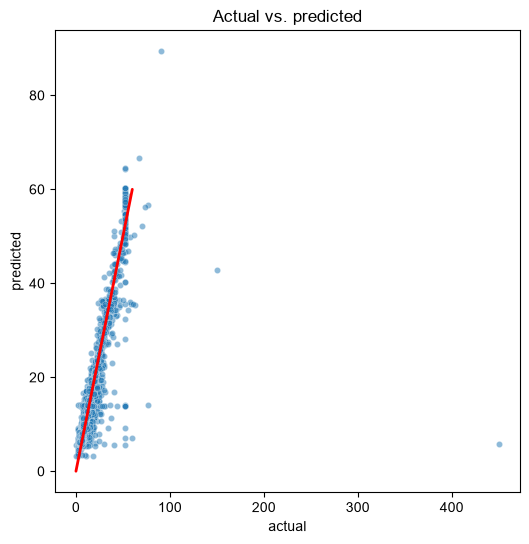

In [37]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.set_theme(style="whitegrid")
sns.scatterplot(x="actual", y="predicted", data=results, s=20, alpha=0.5, ax=ax)

ax.plot([0, 60], [0, 60], c="red", linewidth=2)
ax.set_title("Actual vs. predicted")
plt.show()


In [38]:
sns.histplot(results["residual"], bins=np.arange(-15, 15.5, 0.5))
plt.title("Distribution of the residuals")
plt.xlabel("residual value")
plt.ylabel("count")
plt.close()

print(results["residual"].mean())


-0.07917267295827603


### Scatterplot of the residuals over predicted

In [39]:
sns.scatterplot(x="predicted", y="residual", data=results)
plt.axhline(0, c="red")
plt.title("Scatterplot of residuals over predicted values")
plt.xlabel("predicted value")
plt.ylabel("residual value")
# plt.show()
plt.close()


## Coefficients

In [40]:
coefficients = pd.DataFrame(lr.coef_, columns=X.columns)
print(coefficients)


   passenger_count  mean_distance  mean_duration  rush_hour  VendorID_2
0        -0.012434       7.820689       2.293045   0.100816   -0.065055


Given that the independent variables were standardized using `StandardScaler`, the coefficients represent the expected change in the target variable (`fare_amount`) for each one-standard-deviation increase in the predictor variable, while holding all other variables constant.

- **`mean_distance` (~7.17):** the strongest predictor. A one-standard-deviation increase in the mean distance raises the estimated fare by approximately $7.17.
- **`mean_duration` (~2.77):** also a significant positive impact; a one-standard-deviation increase raises the fare by about $2.77.
- **`passenger_count`, `rush_hour`, `VendorID_2`:** much smaller coefficients, close to zero, indicating a minimal or negligible linear effect on the fare compared to distance and time.

## Conclusion

- **Importance of feature engineering:** the created variables (`mean_distance` and `mean_duration`) are fundamental because they reflect the actual relationship with the trip fare.
- **Predictive power:** trip distance and duration are, by a wide margin, the primary determinants of `fare_amount`, far outweighing factors such as the number of passengers or the vendor.
- **Normalization:** scalers such as `StandardScaler` are essential for fairly comparing the weight of each variable within linear regression models.
- **Model performance:** the multiple linear regression model explains a high proportion of the variance in taxi fares (R² of approximately 0.84 on the training data).
- **Cost drivers:** for every one-standard-deviation increase in trip distance or duration, the fare increases in direct proportion.
- **Identified business rules:** the impact of regulated fixed fares (such as the $52.00 flat rate to JFK Airport) was validated, as was the proper handling of outliers during data preparation to prevent bias in the model.